# INSTRUCCIONES

## OBJETIVOS

Desarrollar competencias básicas para:

1. Lectura y exploración de datos utilizando `pandas`.
2. Limpieza y transformación de datos utilizando `pandas`.
3. Visualización básica de datos utilizando `matplotlib` y `seaborn`.
4. Análisis y preprocesamiento de datos para la formulación de hipótesis de modelos.

## ENTREGABLE

*Reglas para el envío de los entregables*:

- **Forma de envío:**

  Este laboratorio se debe enviar únicamente a través de la plataforma <ins>[Moodle](https://campusvirtual.escuelaing.edu.co/moodle/)</ins> en la actividad definida.

- **Archivo de entrega:**

  Incluyan en un archivo `.zip` los archivos correspondientes al laboratorio, revise <ins>**[How to cite in Jupyter Notebooks](https://gist.github.com/ELS4NTA/2c188b3b7300a726e60d71a58a55f740)**</ins> para citar cualquier recurso utilizado y ver la estructura del proyecto.

- **Nomenclatura para nombrar el archivo de entrega:**

  El archivo deberá ser renombrado en mayúsculas con el siguiente formato: `L03-{color_grupo}-IAIA-{semestre_academico}.zip`

  Ejemplos:

  ```txt
  L03-AZUL-IAIA-2026-1.zip
  L03-ROJO-IAIA-2026-1.zip
  ```

## Herramientas del laboratorio

En este laboratorio trabajaremos con tres bibliotecas fundamentales del ecosistema de Python para ciencia de datos:

- **`pandas`**: Biblioteca para manipulación y análisis de datos. Proporciona estructuras de datos como `Series` (unidimensional) y `DataFrame` (bidimensional, tipo tabla) que facilitan la lectura, limpieza, transformación y exploración de conjuntos de datos. Es el estándar en Python para trabajar con datos tabulares. [Documentación oficial](https://pandas.pydata.org/docs/).

- **`matplotlib`**: Biblioteca base de visualización en Python. Permite crear gráficos estáticos como líneas, barras, dispersión, histogramas, entre otros. Es altamente configurable y sirve como fundamento sobre el cual se construyen otras bibliotecas de visualización. [Documentación oficial](https://matplotlib.org/stable/contents.html).

- **`seaborn`**: Biblioteca de visualización construida sobre `matplotlib`. Simplifica la creación de gráficos comunes (distribuciones, relaciones entre variables, comparaciones por categorías) con menos código y estilos más atractivos por defecto. [Documentación oficial](https://seaborn.pydata.org/).

Revise cuando lo requiera <a href="https://aima.cs.berkeley.edu/global-index.html">(Russell & Norvig, 2021) <cite data-cite="russell2021artificial"></cite></a>

# I. COMPRENDIENDO

En esta sección aprenderá los conceptos básicos de `pandas`, `matplotlib` y `seaborn` a través de ejemplos simples y ejercicios guiados.

## Convenciones de Importación

La comunidad Python ha adoptado una serie de convenciones de nomenclatura para los módulos de uso común:

```python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
```

Esto significa que cuando ve `pd.DataFrame`, se trata de una referencia a la clase `DataFrame` en `pandas`, o cuando ve `plt.show()`, es una referencia a la función `show` de `matplotlib`. Esto se hace porque se considera una mala práctica en el desarrollo de software Python importar todo (`from pandas import *`) de un paquete grande.

Por ahora, solo importaremos `numpy` y `pandas`. Más adelante, cuando lleguemos a la sección de visualización, importaremos `matplotlib` y `seaborn`.

In [340]:
import pandas as pd
from IPython.display import display

## Pandas: Estructuras de Datos

Para empezar a utilizar `pandas`, debe comprender sus dos estructuras de datos principales: `Series` y `DataFrame`. Ambas se construyen a partir de estructuras básicas de Python como **listas** y **diccionarios**.

### `Series`

Una `Series` es un arreglo unidimensional que contiene una secuencia de valores y un arreglo asociado de etiquetas, denominado `index`. Se puede crear a partir de una **lista** o un **diccionario** de Python.

**Creación desde una lista:**

In [341]:
# Desde una lista, el index se asigna automáticamente (0, 1, 2, ...)
series_lista = pd.Series([10, 20, 30, 40])
series_lista

0    10
1    20
2    30
3    40
dtype: int64

In [342]:
# Desde una lista, con un index personalizado
series_index = pd.Series([10, 20, 30, 40], index=['a', 'b', 'c', 'd'])
series_index

a    10
b    20
c    30
d    40
dtype: int64

**Creación desde un diccionario:**

In [343]:
# Desde un diccionario, las llaves se convierten en el index
series_dict = pd.Series({"manzana": 3, "banana": 5, "naranja": 2})
series_dict

manzana    3
banana     5
naranja    2
dtype: int64

#### Ejercicio: Manipulando `Series`


Tiene los siguientes datos de población:

| Estado | Población |
|--------|----------|
| Ohio | 35000 |
| Texas | 71000 |
| Oregon | 16000 |
| Utah | 5000 |

1. Cree la `Series` utilizando un **diccionario** de Python a partir de los datos previos y observe el resultado.
2. Convierta la `Series` nuevamente a un diccionario de Python. Investigue qué método de `Series` se usa para esto.
3. Use `pd.isna()` y `pd.notna()` sobre su `Series`. ¿Qué devuelven? ¿Qué significa `NaN` en el contexto de `pandas`?
4. Asigne un nombre a la `Series` ("Population") y al index ("Estado"). Investigue los atributos `.name` e `.index.name`.

> **Referencia**: [pandas `Series`](https://pandas.pydata.org/docs/reference/series.html) y [Pandas Tutorial](https://www.w3schools.com/python/pandas/default.asp)

In [344]:

seriesExample = pd.Series({"Ohio":35000, "Texas": 71000,"Oregon":16000,"Utah":5000})
seriesExample

# En este caso se usa el .to_dict() para convertir una series a un diccionario clásico de Python
toDict = seriesExample.to_dict()
toDict

# pd.sina() evalua si cada valor de la series es Nulo y notna() lo contrario, es decir si algun valor No es nulo
# NaN significa que es un valor nulo
seriesExample.isna()
seriesExample.notna()

# .name es para agregar el nombre a la Series y .index.name para definir el nombre del index

seriesExample.name = "Population"
seriesExample.index.name = "Estado"

seriesExample


Estado
Ohio      35000
Texas     71000
Oregon    16000
Utah       5000
Name: Population, dtype: int64

### `DataFrame`

Un `DataFrame` representa una tabla de datos con filas y columnas. Cada columna puede tener un tipo de dato diferente. Se puede considerar como un **diccionario de `Series`** que comparten el mismo índice.

La forma más común de construir un `DataFrame` es a partir de un **diccionario de listas** de igual longitud:

In [345]:
data = {
    "state": ["Ohio", "Ohio", "Ohio", "Nevada", "Nevada", "Nevada"],
    "year": [2000, 2001, 2002, 2001, 2002, 2003],
    "pop": [1.5, 1.7, 3.6, 2.4, 2.9, 3.2],
}
frame = pd.DataFrame(data)
frame

,state,year,pop
0,Ohio,2000,1.5
1,Ohio,2001,1.7
2,Ohio,2002,3.6
3,Nevada,2001,2.4
4,Nevada,2002,2.9
5,Nevada,2003,3.2


#### Ejercicio: Manipulando `DataFrame`

1. Use las funciones `head()` y `tail()` sobre `frame`. ¿Qué hacen? ¿Qué parámetro aceptan?
2. Use `describe()` sobre `frame`. ¿Qué información proporciona? ¿Qué columnas incluye en el resumen y por qué?
3. Cree un nuevo `DataFrame` a partir de `data` usando el parámetro `columns`. Agregue columnas que no existan en `data` y observe qué sucede.
4. Extraiga los nombres de las columnas de su `DataFrame`. Investigue cómo hacerlo.
5. Modifique las nuevas columnas agregadas con un valor constante.
6. Cree una `Series` con nuevos datos y agréguela como columna "*learning*" al `DataFrame`.
7. Cree una columna "*eastern*" que sea `True` si el estado es Ohio y `False` en caso contrario.
8. Elimine la columna "*pop*" usando la palabra reservada `del` de Python. Observe el resultado.

> **Referencia**: [pandas `DataFrame`](https://pandas.pydata.org/docs/reference/frame.html) y [Pandas Tutorial](https://www.w3schools.com/python/pandas/default.asp)

In [346]:
# 1. 
# frame.head(n) sirve para mostrar los primeros n filas 
frame.head(2)
# frame.tail(n) sirve para mostrar las ultimas n filas
frame.tail(1)

# 2.
# Describe para las columnas numericas del Df, resumenes de estadisticas como cuenta total, promedio o porcentajes
frame.describe()

# 3.
#Si se agrega una columna que no existe en los datos, se agrega como NaN (Nulo)
dataFrame = pd.DataFrame(data,columns=["year", "state", "pop", "debt","pib"])
dataFrame

# 4. 
columns = dataFrame.columns   
columns

# 5. 
#Se usa la asignación y se genera el valor para todos los valores de esa columna
dataFrame["debt"] = 5
dataFrame["pib"] = 4.2
dataFrame

# 6. 
seriesL = pd.Series([10,20,0,40,55,67,7,7,7,7,7,7])
dataFrame["learning"] = seriesL
dataFrame

# 7. Se usa una comparacion sobre la columna a agregar, si el valor de state es igual a Ohio, es True, de lo contrario False 
dataFrame["eastern"] = frame["state"] == "Ohio"
dataFrame

# 8. 
del dataFrame["pop"]
dataFrame

,year,state,debt,pib,learning,eastern
0,2000,Ohio,5,4.2,10,True
1,2001,Ohio,5,4.2,20,True
2,2002,Ohio,5,4.2,0,True
3,2001,Nevada,5,4.2,40,False
4,2002,Nevada,5,4.2,55,False
5,2003,Nevada,5,4.2,67,False


### Lectura de Datos desde Archivos

En la práctica, rara vez se crean `DataFrames` manualmente. Lo más común es **leer datos desde archivos** en diferentes formatos. `pandas` ofrece múltiples funciones de lectura según el tipo de fuente:

![pandasread](./images/pandasread.png)

La función más usada es `pd.read_csv()`:

```python
# Desde un archivo local
df = pd.read_csv("ruta/al/archivo.csv")

# Desde una URL
df = pd.read_csv("https://ejemplo.com/datos.csv")

# Especificando la primera columna como índice
df = pd.read_csv("archivo.csv", index_col=0)
```

#### Ejercicio: Cargando y explorando un dataset

1. Cargue el conjunto de datos `data/pokemon.csv` usando `pd.read_csv()`. Use el parámetro `index_col=0` para que la primera columna sea el índice.
2. Observe los primeros 5 registros con `head()` y los últimos 5 con `tail()`.
3. Use `info()` para ver información general del `DataFrame`: ¿Cuántas filas y columnas tiene? ¿Hay datos faltantes? ¿Qué tipos de datos tiene cada columna?
4. Use `describe()` para obtener el resumen estadístico. Explique qué representa cada fila: `count`, `mean`, `std`, `min`, `25%`, `50%`, `75%`, `max`.
5. Use `shape` y `dtypes` para verificar dimensiones y tipos de datos.

In [347]:
# 1. 
df = pd.read_csv("data/pokemon.csv", index_col = 0)

# 2. 
df.head(5)
df.tail(5)

# 3. Nos dice datos como: 800 filas y 12 columnas, y Type2 tiene 414 datos no nulos por lo que le faltan 586, y los tipos en general de entrada son 
# strings, enteros de 64 bits y boleanos.
df.info()

# 4. count representa el numero de valores no nulos totales, mean el promedio, std la desviacion estandar muestral, min el valor minimo, los porcentajes
# son los cuartiles estadísticos y max el máximo valor.
df.describe()

# 5. 
df.shape # Muestra la dimension en filas y columnas (800,12)
df.dtypes #Muestra los tipos de datos del frame a detalle


<class 'pandas.DataFrame'>
Index: 800 entries, 1 to 721
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Name        800 non-null    str  
 1   Type 1      800 non-null    str  
 2   Type 2      414 non-null    str  
 3   Total       800 non-null    int64
 4   HP          800 non-null    int64
 5   Attack      800 non-null    int64
 6   Defense     800 non-null    int64
 7   Sp. Atk     800 non-null    int64
 8   Sp. Def     800 non-null    int64
 9   Speed       800 non-null    int64
 10  Generation  800 non-null    int64
 11  Legendary   800 non-null    bool 
dtypes: bool(1), int64(8), str(3)
memory usage: 75.8 KB


Name            str
Type 1          str
Type 2          str
Total         int64
HP            int64
Attack        int64
Defense       int64
Sp. Atk       int64
Sp. Def       int64
Speed         int64
Generation    int64
Legendary      bool
dtype: object

### Selección de Datos en `DataFrame`

Aquí se muestra un resumen de las formas más comunes de seleccionar datos en un `DataFrame` `df`:

![pandasselecting](./images/pandasselecting.png)

| Tipo | Descripción |
| :--- | :--- |
| `df[columna]` | Selecciona una columna o secuencia de columnas. |
| `df.loc[filas]` | Selecciona filas por **etiqueta** (nombre del índice). |
| `df.loc[:, columnas]` | Selecciona columnas por **etiqueta**. |
| `df.loc[filas, columnas]` | Selecciona filas y columnas por **etiqueta**. |
| `df.iloc[filas]` | Selecciona filas por **posición** (número entero). |
| `df.iloc[:, columnas]` | Selecciona columnas por **posición**. |
| `df.iloc[filas, columnas]` | Selecciona filas y columnas por **posición**. |

#### Ejercicio: Selección de datos

Usando el `DataFrame` de Pokémon cargado anteriormente:

1. Seleccione la columna `Attack` usando `df['Attack']`. ¿Qué tipo de objeto devuelve?
2. Seleccione las columnas `Attack` y `Defense` al mismo tiempo.
3. Use `loc` para seleccionar el Pokémon con índice 1 (Bulbasaur). ¿Qué información obtiene?
4. Use `iloc` para seleccionar las primeras 3 filas y las columnas del 1 al 4.
5. Seleccione todos los Pokémon cuyo `Attack` sea mayor a 100. ¿Cuántos son?

In [348]:
# 1. Devuelve una Series de pandas.

df["Attack"]
type(df["Attack"])

# 2. Se puede usar con .loc o con doble corchete cuadrado

df.loc[:, ["Attack","Defense"]]
df[["Attack","Defense"]]

# 3. 
df.loc[1]

# 4. Se usa el rebanado y se dice que filas del 0 al 2 (Tres primeras) y columnas del 1 al 4
df.iloc[0:3,1:5]

# 5. Son 170
above100Attack = df[df["Attack"] > 100]
len(above100Attack)




170

### Manejo de datos faltantes

Los datos faltantes son comunes en conjuntos de datos reales. `pandas` representa los datos faltantes como `NaN` (*Not a Number*) y ofrece funciones para detectarlos, eliminarlos o rellenarlos.

Las funciones principales son:

- `df.isnull()` y `pd.isna()`: Detecta valores faltantes.
- `df.dropna()`: Elimina filas o columnas con valores faltantes.
- `df.fillna(valor)`: Rellena valores faltantes con un valor dado.

#### El parámetro `axis`

Muchas funciones de `pandas` (como `dropna()`, `sum()`, `mean()`, `apply()`, `drop()`) reciben un parámetro **`axis`** que indica la **dirección** en la que se aplica la operación. Este concepto es fundamental y se usa en toda la biblioteca:

- **`axis=0`** (o `axis='index'`): opera sobre las **filas** (recorre de arriba hacia abajo). Es el valor por defecto.
- **`axis=1`** (o `axis='columns'`): opera sobre las **columnas** (recorre de izquierda a derecha).

![pandasaxis](./images/pandasaxis.png)

**Ejemplos:**

- `df.dropna(axis=0)` → elimina las **filas** que tengan algún valor faltante.
- `df.dropna(axis=1)` → elimina las **columnas** que tengan algún valor faltante.
- `df.sum(axis=0)` → suma cada **columna** (recorriendo las filas hacia abajo).
- `df.sum(axis=1)` → suma cada **fila** (recorriendo las columnas hacia la derecha).

#### Ejercicio: Datos faltantes

1. Cree un `DataFrame` con datos faltantes (use `np.nan` o `None`) y aplique `dropna()` y `fillna()` para observar cómo se comportan.
2. Con `dropna()`: elimine datos faltantes solo de las filas (`axis=0`) y luego solo de las columnas (`axis=1`). ¿Cuál es la diferencia?
3. Con `fillna()`: rellene los datos faltantes con un valor constante (por ejemplo, 0 o la media de la columna).

In [349]:

# 1. 
import numpy as np
dataFrameNaN = pd.DataFrame(
    {
        'Nombre': ['Pikachu', 'Charizard', np.nan, 'Gengar', 'Eevee'],
        'Ataque': [55.0, np.nan, 85.0, 65.0, np.nan],
        'Defensa': [40.0, 78.0, 95.0, 60.0, 50.0],
        'Tipo 2': [np.nan, 'Flying', 'Ground', 'Poison', None],
    }
)


# 2. Dependiendo si es el eje de filas o columnas, elimina las filas o columnas que contengan algun valor Nulo o NaN

dataFrameNaN.dropna(axis= 0)
dataFrameNaN.dropna(axis= 1)

# 3.
dataFrameNaN.fillna(67)



,Nombre,Ataque,Defensa,Tipo 2
0,Pikachu,55.0,40.0,67
1,Charizard,67.0,78.0,Flying
2,67,85.0,95.0,Ground
3,Gengar,65.0,60.0,Poison
4,Eevee,67.0,50.0,67


### Transformación de datos

![pandastransform](./images/pandastransform.png)

#### Eliminando duplicados

1. Observe el `DataFrame` creado a partir de `data` (abajo).
2. Use `duplicated()` para identificar filas duplicadas y `drop_duplicates()` para eliminarlas. No modifique el `DataFrame` original.
3. Agregue una columna `data["v1"] = range(7)` y aplique `drop_duplicates()` especificando el subconjunto de columnas `["k1"]`. Observe el resultado.

In [350]:
data = pd.DataFrame({"k1": ["one", "two"] * 3 + ["two"], "k2": [1, 1, 2, 3, 3, 4, 4]})

In [351]:
# 2. 
data.duplicated()
sinDuplicados = data.drop_duplicates()

# 3. Al elegir k1 como columna, se eliminan todos los duplicados en K1
data["v1"] = range(7)
data.drop_duplicates(subset=["k1"])




,k1,k2,v1
0,one,1,0
1,two,1,1


#### Transformación usando `map()` y `replace()`

En muchos conjuntos de datos necesitará transformar valores de una columna. Antes de ver cómo hacerlo en `pandas`, repasemos la función `map()` de Python.

**`map()` en Python básico:**

La función built-in `map(función, iterable)` aplica una función a cada elemento de un iterable (lista, tupla, etc.) y devuelve un iterador con los resultados:

```python
# Ejemplo: convertir una lista de números a sus cuadrados
numeros = [1, 2, 3, 4]
cuadrados = list(map(lambda x: x ** 2, numeros))
# Resultado: [1, 4, 9, 16]

# Ejemplo: convertir una lista de strings a mayúsculas
nombres = ["alice", "bob", "charlie"]
mayusculas = list(map(str.upper, nombres))
# Resultado: ["ALICE", "BOB", "CHARLIE"]
```

**`map()` en `pandas`:**

En `pandas`, las `Series` tienen su propio método `.map()` que funciona de forma similar, pero además acepta un **diccionario** como argumento para hacer correspondencias directas:

- **Con un diccionario:** transforma cada valor buscándolo en el diccionario.
- **Con una función:** aplica la función a cada elemento de la `Series`.

In [352]:
# Ejemplo de map() en pandas con un diccionario
ejemplo = pd.Series(["gato", "perro", "gato", "pez"])
traduccion = {"gato": "cat", "perro": "dog", "pez": "fish"}
print("\nOriginal:")
print(ejemplo)
print("\nTraducido con map():")
print(ejemplo.map(traduccion))


Original:
0     gato
1    perro
2     gato
3      pez
dtype: str

Traducido con map():
0     cat
1     dog
2     cat
3    fish
dtype: str


In [353]:
data = pd.DataFrame(
    data={
        "food": ["bacon", "pulled pork", "bacon", "pastrami", "corned beef", "bacon", "pastrami", "honey ham", "nova lox"],
        "ounces": [4, 3, 12, 6, 7.5, 8, 3, 5, 6],
    }
)

Supongamos que desea añadir una columna que indique el tipo de animal del que procede cada alimento:

In [354]:
meat_to_animal = {
    "bacon": "pig",
    "pulled pork": "pig",
    "pastrami": "cow",
    "corned beef": "cow",
    "honey ham": "pig",
    "nova lox": "salmon",
}

**Ejercicio:**

1. Use `map()` con el diccionario `meat_to_animal` para crear una nueva columna `animal` en el `DataFrame`.
2. Cree una función `get_animal(meat: str) -> str` que devuelva el tipo de animal dado un tipo de carne. Use esta función con `map()` para crear la columna `animal`.

In [355]:

# 1. 
data["animal"] = data["food"].map(meat_to_animal)
data

# 2. 
def get_animal(meat: str) -> str:
    return meat_to_animal.get(meat)

data["animal"] = data["food"].map(get_animal)
data

,food,ounces,animal
0,bacon,4.0,pig
1,pulled pork,3.0,pig
2,bacon,12.0,pig
3,pastrami,6.0,cow
4,corned beef,7.5,cow
5,bacon,8.0,pig
6,pastrami,3.0,cow
7,honey ham,5.0,pig
8,nova lox,6.0,salmon


#### Reemplazando valores con `replace()`

`replace()` permite sustituir valores específicos de forma directa, sin necesidad de definir un mapeo completo:

In [356]:
data = pd.Series([1., -999., 2., -999., -1000., 3.])

**Ejercicio:**

1. Los valores `-999` representan datos faltantes. Reemplácelos por `np.nan` usando `replace()`.
2. Ahora tanto `-999` como `-1000` son datos faltantes. Reemplace ambos por `np.nan` en una sola operación usando `replace()`.

In [357]:
# 1. 

dataRemplazado = data.replace(-999,np.nan)
dataRemplazado

# 2. 

dataRemplazado = data.replace([-999,-1000],np.nan)
dataRemplazado



0    1.0
1    NaN
2    2.0
3    NaN
4    NaN
5    3.0
dtype: float64

## Matplotlib: Visualización Básica

![visualization](./images/visualization.png)

Antes de usar `seaborn`, es importante conocer los fundamentos de `matplotlib`, la biblioteca base de visualización en Python. `matplotlib` le da control total sobre los elementos de un gráfico: ejes, títulos, colores, tamaños, etc.

Importemos la biblioteca de visualización:

In [358]:
import matplotlib.pyplot as plt

### Conceptos básicos de `matplotlib`

En `matplotlib`, un gráfico se compone de:

- **`Figure`**: El lienzo o contenedor principal del gráfico.
- **`Axes`**: El área donde se dibujan los datos (un `Figure` puede tener múltiples `Axes`).

Veamos ejemplos de los tres tipos de gráficos más comunes:

**Gráfico de línea** — `plt.plot()`: conecta puntos con una línea, útil para datos secuenciales.

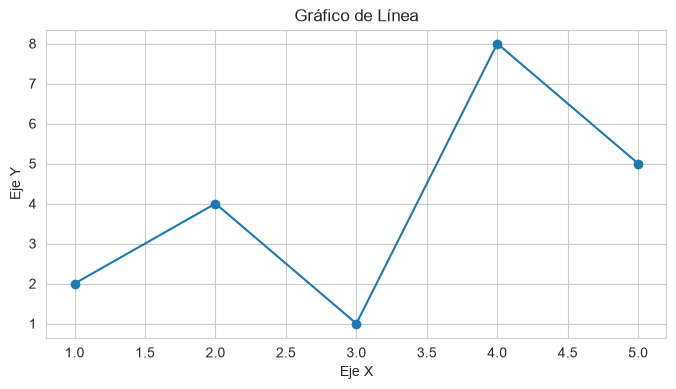

In [359]:
# Gráfico de línea
x = [1, 2, 3, 4, 5]
y = [2, 4, 1, 8, 5]

plt.figure(figsize=(8, 4))
plt.plot(x, y, marker='o')
plt.title("Gráfico de Línea")
plt.xlabel("Eje X")
plt.ylabel("Eje Y")
plt.show()

**Gráfico de barras** — `plt.bar()`: compara cantidades entre categorías.

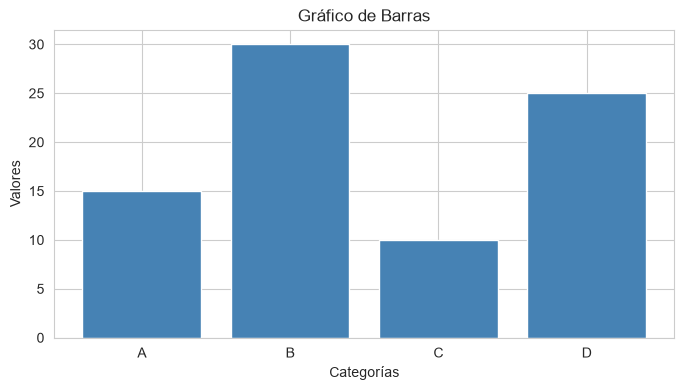

In [360]:
# Gráfico de barras
categorias = ["A", "B", "C", "D"]
valores = [15, 30, 10, 25]

plt.figure(figsize=(8, 4))
plt.bar(categorias, valores, color="steelblue")
plt.title("Gráfico de Barras")
plt.xlabel("Categorías")
plt.ylabel("Valores")
plt.show()

**Gráfico de dispersión** — `plt.scatter()`: muestra la relación entre dos variables numéricas.

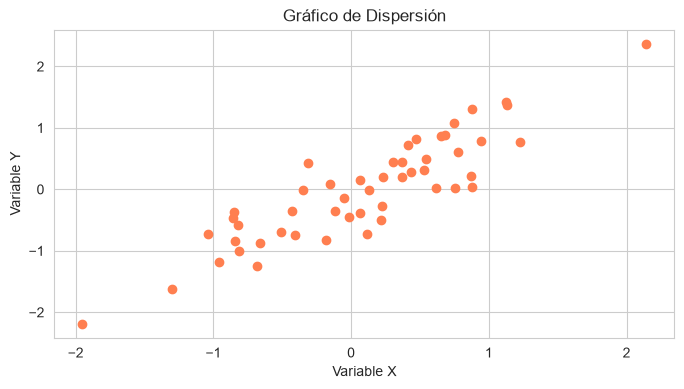

In [361]:
# Gráfico de dispersión
import numpy as np

rng = np.random.default_rng(42)
x = rng.standard_normal(50)
y = x + rng.standard_normal(50) * 0.5

plt.figure(figsize=(8, 4))
plt.scatter(x, y, color="coral")
plt.title("Gráfico de Dispersión")
plt.xlabel("Variable X")
plt.ylabel("Variable Y")
plt.show()

**Múltiples subgráficos** — `plt.subplots()`: permite crear varios gráficos en una sola figura.

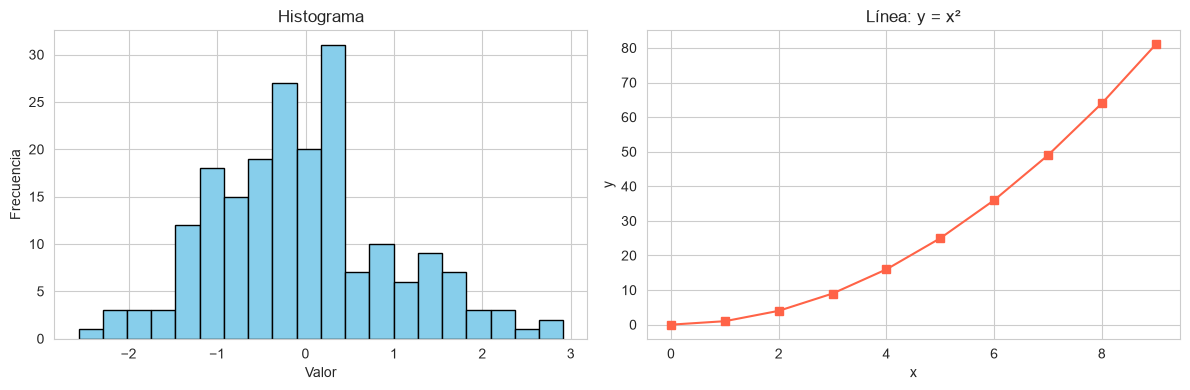

In [362]:
# Múltiples subgráficos en una sola figura
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Subgráfico 1: histograma
datos = rng.standard_normal(200)
axes[0].hist(datos, bins=20, color="skyblue", edgecolor="black")
axes[0].set_title("Histograma")
axes[0].set_xlabel("Valor")
axes[0].set_ylabel("Frecuencia")

# Subgráfico 2: gráfico de línea
x = range(10)
y = [i ** 2 for i in x]
axes[1].plot(x, y, marker='s', color="tomato")
axes[1].set_title("Línea: y = x²")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")

plt.tight_layout()
plt.show()

#### Ejercicio: Gráficos básicos con `matplotlib`

Cargue el dataset de Pokémon si no lo tiene cargado:

```python
pokemon = pd.read_csv("data/pokemon.csv", index_col=0)
```

1. Cree un **histograma** de la columna `Attack` usando `plt.hist()`. Agregue título y etiquetas a los ejes.
2. Cree un **gráfico de dispersión** de `Attack` vs `Defense` usando `plt.scatter()`. ¿Observa alguna relación?
3. Cree una figura con **2 subgráficos** lado a lado usando `plt.subplots(1, 2, figsize=(12, 5))`. En el primero dibuje un histograma de `HP` y en el segundo un histograma de `Speed`.
4. ¿Qué función usa para ajustar el tamaño de la figura? ¿Y para rotar las etiquetas del eje x?

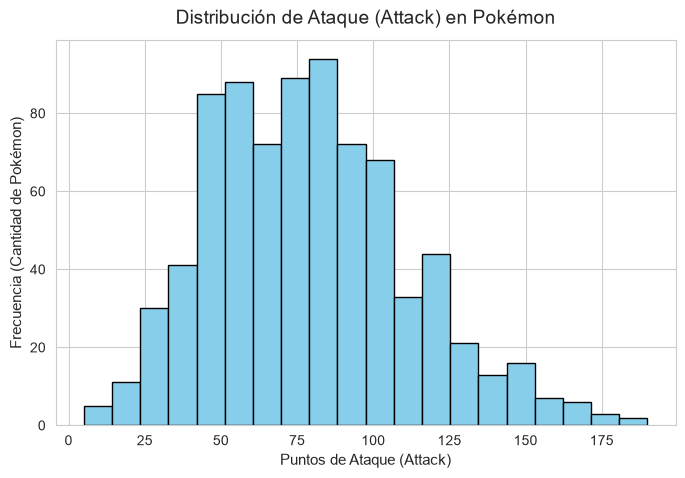

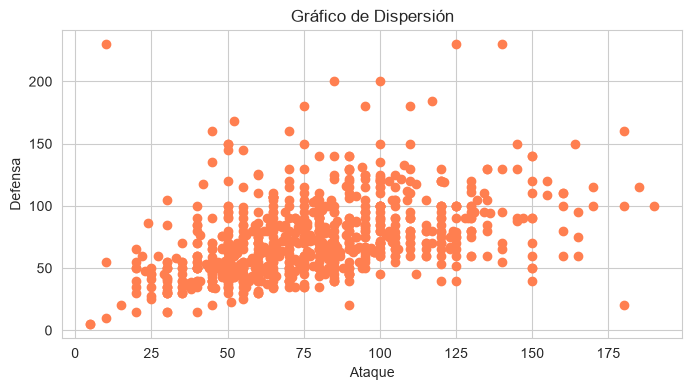

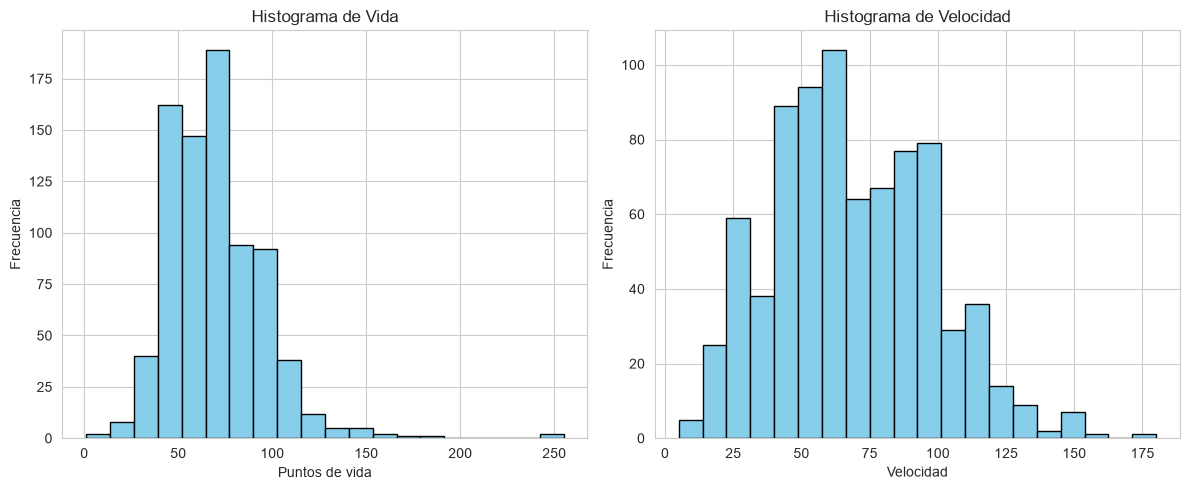

In [363]:
pokemon = pd.read_csv("data/pokemon.csv", index_col=0)

# 1. 

plt.figure(figsize=(8, 5))
plt.hist(pokemon["Attack"], bins=20, color="skyblue", edgecolor="black")

plt.title("Distribución de Ataque (Attack) en Pokémon", fontsize=14, pad=12)
plt.xlabel("Puntos de Ataque (Attack)", fontsize=11)
plt.ylabel("Frecuencia (Cantidad de Pokémon)", fontsize=11)


plt.show()

# 2. A medida que aumenta el ataque, lo hace también la defensa

plt.figure(figsize=(8, 4))
plt.scatter(pokemon["Attack"], pokemon["Defense"], color="coral")
plt.title("Gráfico de Dispersión")
plt.xlabel("Ataque")
plt.ylabel("Defensa")
plt.show()

# 3.

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Histograma HP

axes[0].hist(pokemon["HP"], bins=20, color="skyblue", edgecolor="black")
axes[0].set_title("Histograma de Vida")
axes[0].set_xlabel("Puntos de vida")
axes[0].set_ylabel("Frecuencia")

# Gráfico de línea de Speed
axes[1].hist(pokemon["Speed"], bins=20, color="skyblue", edgecolor="black")
axes[1].set_title("Histograma de Velocidad")
axes[1].set_xlabel("Velocidad")
axes[1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

# 4. Se usa figure para el tamaño y xticks para rotar los ejes 
#plt.figure(figsize=(10, 6))
#plt.xticks(rotation=45, ha="right")

## Seaborn: Visualización de Datos

`seaborn` se construye sobre `matplotlib` y facilita la creación de gráficos con menos código. Mientras `matplotlib` requiere configurar manualmente muchos detalles, `seaborn` ofrece funciones de alto nivel que generan visualizaciones informativas automáticamente.

A continuación exploraremos los tipos de gráficos más comunes de forma sistemática, organizados según el **tipo de variable** que representan.

In [364]:
import seaborn as sns

# Cargar el dataset de Pokémon
pokemon = pd.read_csv("data/pokemon.csv", index_col=0)
pokemon.head()

,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
#,,,,,,,,,,,,
1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False
3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False
3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,False
4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False


In [365]:
pokemon.describe()

,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation
count,800.00000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.00000
mean,435.10250,69.258750,79.001250,73.842500,72.820000,71.902500,68.277500,3.32375
std,119.96304,25.534669,32.457366,31.183501,32.722294,27.828916,29.060474,1.66129
min,180.00000,1.000000,5.000000,5.000000,10.000000,20.000000,5.000000,1.00000
25%,330.00000,50.000000,55.000000,50.000000,49.750000,50.000000,45.000000,2.00000
50%,450.00000,65.000000,75.000000,70.000000,65.000000,70.000000,65.000000,3.00000
75%,515.00000,80.000000,100.000000,90.000000,95.000000,90.000000,90.000000,5.00000
max,780.00000,255.000000,190.000000,230.000000,194.000000,230.000000,180.000000,6.00000


### Tipos de variables y análisis

Antes de visualizar datos, es importante entender los **tipos de variables** y cómo se analizan:

#### Variables según su tipo

- **Numéricas** (cuantitativas): representan cantidades medibles. Ejemplos: `Attack`, `Defense`, `Speed`, `HP`.
- **Categóricas** (cualitativas): representan grupos o categorías. Ejemplos: `Type 1`, `Generation`, `Legendary`.

#### Análisis univariado vs bivariado

- **Univariado**: analiza **una sola variable** a la vez. El objetivo es entender su distribución (¿cómo se reparten los valores? ¿hay valores atípicos? ¿cuál es el valor más frecuente?).

  | Tipo de variable | Gráfico recomendado | ¿Qué muestra? |
  | :--- | :--- | :--- |
  | Numérica | `histplot`, `kdeplot` | Distribución de valores, forma, sesgo |
  | Categórica | `countplot` | Frecuencia de cada categoría |

- **Bivariado**: analiza la **relación entre dos variables**. El objetivo es descubrir si existe alguna asociación o patrón entre ellas.

  | Combinación | Gráfico recomendado | ¿Qué muestra? |
  | :--- | :--- | :--- |
  | Numérica vs Numérica | `scatterplot`, `lmplot` | Correlación, tendencias |
  | Categórica vs Numérica | `boxplot`, `violinplot` | Distribución por grupo |
  | Categórica vs Categórica | `heatmap` (sobre `crosstab`) | Frecuencia cruzada |

En las siguientes secciones exploraremos cada combinación con ejemplos prácticos.

### Variable numérica univariada: `histplot`

El histograma muestra la **distribución** de una variable numérica, es decir, cómo se reparten los valores en diferentes rangos.

1. Cree un histograma de `Attack` usando `sns.histplot(data=pokemon, x='Attack')`.
2. Agregue una curva de densidad con `kde=True`. ¿Qué información adicional aporta?
3. Cree un histograma de `Speed`. ¿La distribución es simétrica o sesgada?

<Axes: xlabel='Attack', ylabel='Count'>

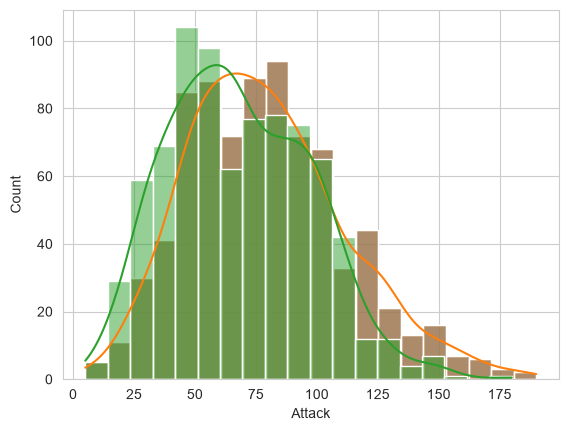

In [366]:
# 1. 
sns.histplot(data=pokemon, x='Attack')

# 2.
sns.histplot(data=pokemon, x='Attack', kde = True)

# 3.
sns.histplot(data=pokemon, x="Speed", kde= True)


### Variable categórica univariada: `countplot`

El gráfico de conteo muestra **cuántos elementos** hay en cada categoría de una variable categórica.

1. Cree un gráfico de conteo de `Type 1` usando `sns.countplot(data=pokemon, x="Type 1")`.
2. Rote las etiquetas del eje x con `plt.xticks(rotation=45)` para mejor legibilidad.
3. ¿Cuál es el tipo de Pokémon más común? ¿Cuál es el menos común?

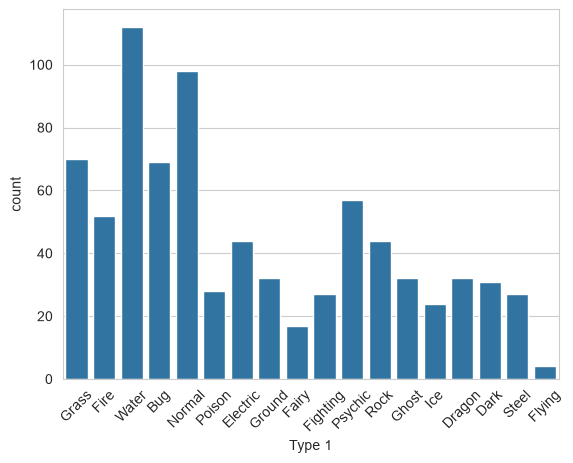

In [367]:
# 1. 
sns.countplot(data=pokemon, x="Type 1")

# 2. 
plt.xticks(rotation=45)

plt.show()

# 3. El tipo más compun es Agua y el menos comun es Volador

### Numérica vs numérica: `scatterplot`

El gráfico de dispersión muestra la **relación entre dos variables numéricas**. Cada punto representa una observación.

1. Cree un gráfico de dispersión de `Attack` vs `Defense` usando `sns.scatterplot(data=pokemon, x="Attack", y="Defense")`. ¿Observa alguna relación?
2. Coloree los puntos según `Generation` usando el parámetro `hue="Generation"`. ¿Nota diferencias entre generaciones?
3. Use `sns.lmplot(data=pokemon, x='Attack', y='Defense', fit_reg=False, hue='Generation')` para obtener un resultado similar. ¿Qué pasa si cambia `fit_reg=True`?

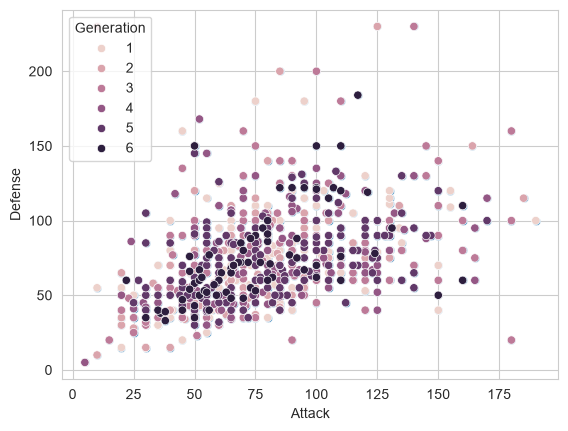

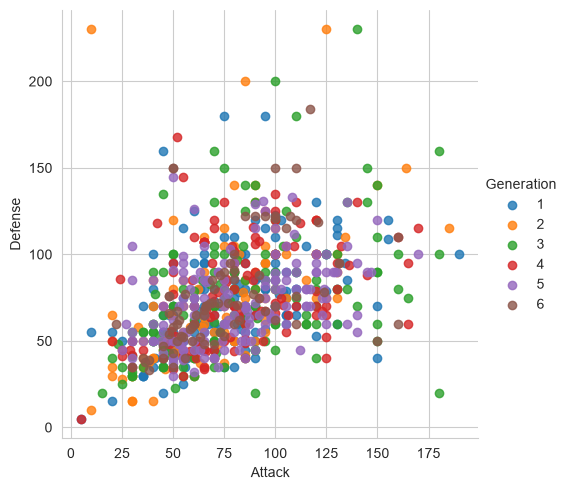

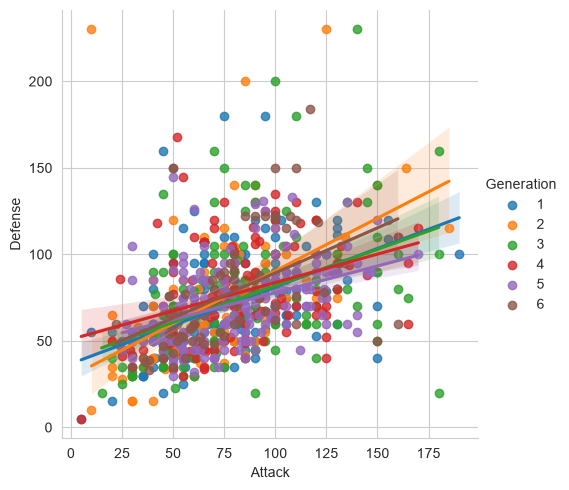

In [368]:
# 1. Sí pues se observa una correlación y es que a mayor ataque, suele haber mayor defensa, aunque hay mucha dispersión.
sns.scatterplot(data=pokemon, x="Attack", y="Defense")

# 2. Se notan agrupaciones, pero las generaciones están bastante mezcladas a lo largo de la distribución.
sns.scatterplot(data=pokemon, x="Attack", y="Defense", hue="Generation")

# 3.Se dibuja una línea de regresión lineal para cada generación
sns.lmplot(data=pokemon, x='Attack', y='Defense', fit_reg=False, hue='Generation')
sns.lmplot(data=pokemon, x='Attack', y='Defense', fit_reg=True, hue='Generation')

### Categórica vs numérica: `boxplot`

El diagrama de cajas compara la **distribución de una variable numérica** entre diferentes categorías. Muestra resúmenes de los datos.

1. Cree un gráfico de cajas comparando `Attack` por `Type 1` usando `sns.boxplot(data=pokemon, x='Type 1', y='Attack')`. Use `plt.figure(figsize=(12, 6))` y rote las etiquetas.
2. ¿Cuál tipo de Pokémon tiene el ataque más fuerte (mediana más alta)? ¿Cuál el más débil?
3. ¿Qué representan los puntos individuales fuera de los "bigotes" del diagrama de cajas?

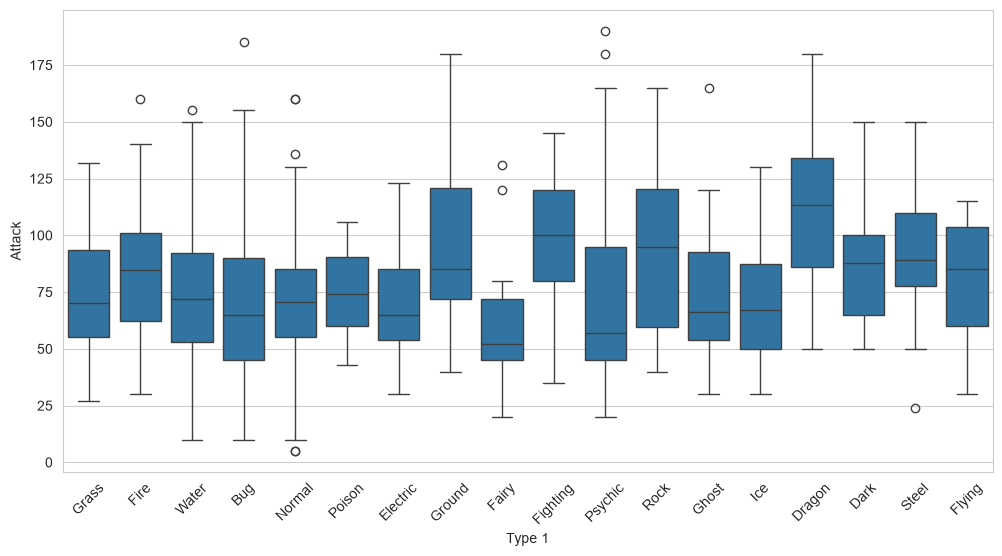

In [369]:
# 1. 
plt.figure(figsize=(12, 6))
sns.boxplot(data=pokemon, x='Type 1', y='Attack')
plt.xticks(rotation=45)
plt.show()

# 2.  El tipo con ataque más fuerte es Dragon. El más débil es Bug o Fairy.

# 3. Representan valores atípicos estadísticos que se salen de los rangos especificados


### Categórica vs categórica: `heatmap` sobre tabla de contingencia

Para ver la relación entre dos variables categóricas, se puede crear una **tabla de contingencia** (conteo cruzado) y visualizarla con un mapa de calor.

1. Cree una tabla de contingencia entre `Type 1` y `Generation` usando `pd.crosstab(pokemon["Type 1"], pokemon["Generation"])`.
2. Visualícela con `sns.heatmap()` usando `annot=True` y `cmap="YlOrRd"`.
3. ¿Qué combinación de tipo y generación tiene más Pokémon?

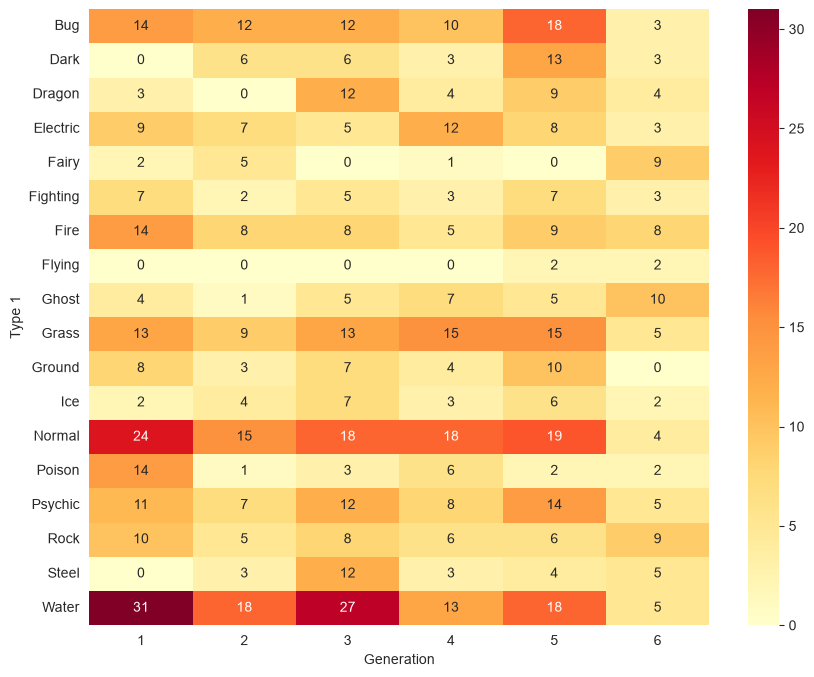

In [370]:
# 1. 
contingencia = pd.crosstab(
    pokemon["Type 1"].reset_index(drop=True), 
    pokemon["Generation"].reset_index(drop=True)
)

# 2. 
plt.figure(figsize=(10, 8))
sns.heatmap(contingencia, annot=True, cmap="YlOrRd")

plt.show()

# 3. 
# La combinación Water y Generación 1 es usualmente la que tiene más Pokémon en la tabla.



### Resumen de gráficos y personalización

`seaborn` incluye temas de estilo que permiten cambiar la apariencia de los gráficos. El tema predeterminado es `darkgrid`.

1. Cree un gráfico de cajas general con **todas las columnas numéricas** del dataset de Pokémon, usando `plt.figure(figsize=(10, 6))`. Observando las escalas, ¿qué columnas tienen rangos muy diferentes al resto? ¿Cuáles no aportan información útil para comparar?
2. Elimine del `DataFrame` las columnas que identificó como no informativas usando `drop()`. Grafique de nuevo el boxplot sin esas columnas y explique por qué las eliminó.
3. Cambie el estilo a `whitegrid` con `sns.set_style("whitegrid")` y cree un gráfico de violines (`sns.violinplot()`) comparando `Type 1` con `Attack`. ¿Qué información adicional da el violinplot respecto al boxplot?

Siéntase libre de explorar la [galería oficial de Seaborn](https://seaborn.pydata.org/examples/) como referencia.

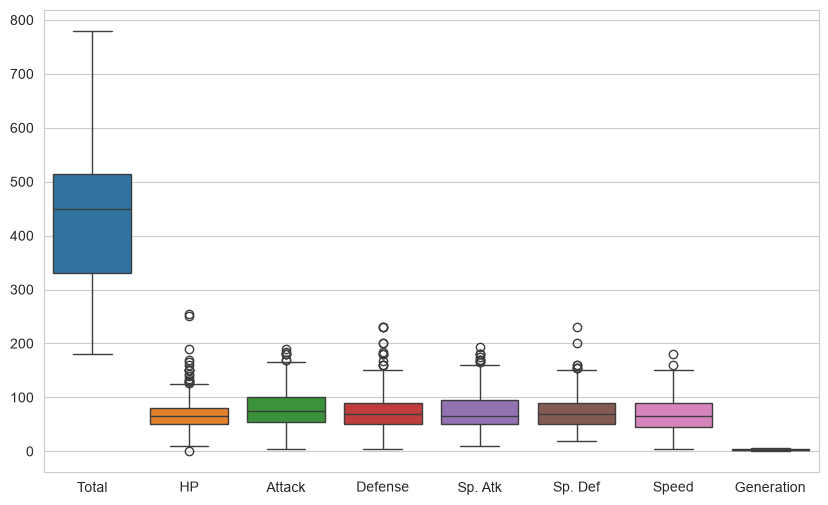

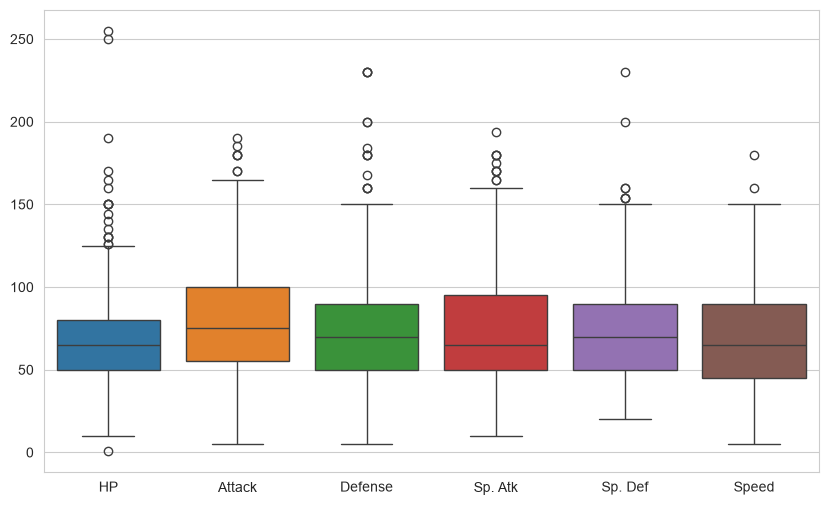

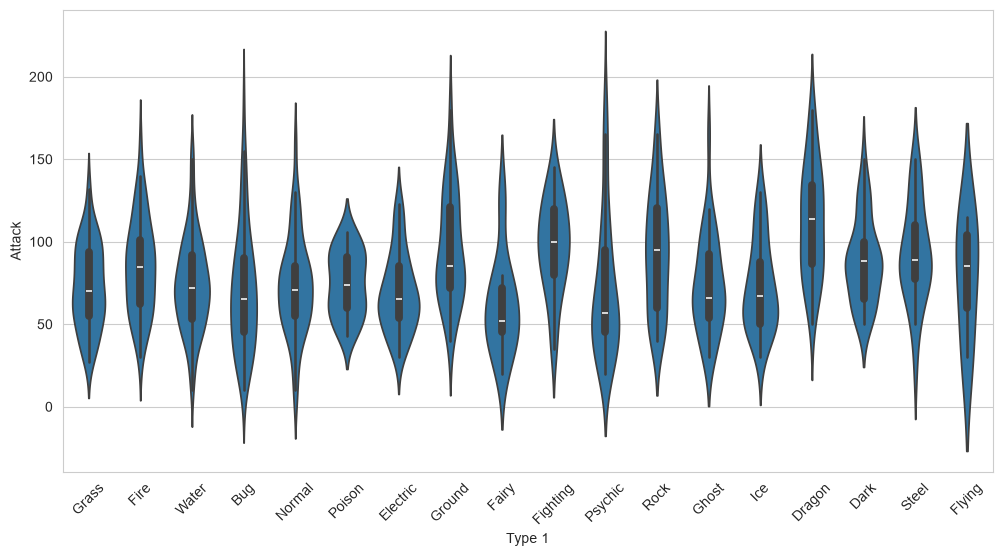

In [371]:
# 1. Las columnas 'Total' y 'Generation' tienen escalas muy diferentes. 
plt.figure(figsize=(10, 6))
sns.boxplot(data=pokemon.select_dtypes(include='number'))


# 2. Se eliminan para poder comparar apropiadamente la distribución
pokemon_reducido = pokemon.drop(columns=['Total', 'Generation'])
plt.figure(figsize=(10, 6))
sns.boxplot(data=pokemon_reducido.select_dtypes(include='number'))

# 3. El violinplot además de los cuartiles muestra la densidad de probabilidad, permitiendo ver dónde se concentran más los valores dentro de cada grupo.
sns.set_style("whitegrid")
plt.figure(figsize=(12, 6))
sns.violinplot(data=pokemon, x='Type 1', y='Attack')
plt.xticks(rotation=45)

plt.show()


# II. EXPLORANDO

En esta sección aplicará lo aprendido de forma **guiada**, siguiendo un proceso paso a paso de análisis y preprocesamiento de datos. Trabajaremos con el dataset de Pokémon para cubrir el ciclo completo:

**Cargar → Explorar → Visualizar → Limpiar → Transformar → Visualizar → Concluir**

## Paso 1: Carga y exploración inicial

1. Cargue el dataset `data/pokemon.csv` con `index_col=0`.
2. Use `info()` y `describe()` para tener una visión general.
3. ¿Cuántos datos faltantes hay en cada columna? Use `isnull().sum()`.
4. ¿Cuántos valores únicos tiene cada columna categórica? Use `nunique()` o `value_counts()`.

In [372]:
# 1.
pokemon = pd.read_csv("data/pokemon.csv", index_col=0)

# 2.
pokemon.info()
pokemon.describe()

# 3. 800 Datos
pokemon.isnull().sum()

# 4.Del Type 1 y 2 son 18 

pokemon.select_dtypes(include=['object', 'str']).nunique()


<class 'pandas.DataFrame'>
Index: 800 entries, 1 to 721
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Name        800 non-null    str  
 1   Type 1      800 non-null    str  
 2   Type 2      414 non-null    str  
 3   Total       800 non-null    int64
 4   HP          800 non-null    int64
 5   Attack      800 non-null    int64
 6   Defense     800 non-null    int64
 7   Sp. Atk     800 non-null    int64
 8   Sp. Def     800 non-null    int64
 9   Speed       800 non-null    int64
 10  Generation  800 non-null    int64
 11  Legendary   800 non-null    bool 
dtypes: bool(1), int64(8), str(3)
memory usage: 75.8 KB


Name      800
Type 1     18
Type 2     18
dtype: int64

## Paso 2: Visualización exploratoria inicial

Antes de limpiar o transformar, es fundamental **entender los datos visualmente**.

1. Cree un `histplot` para cada variable numérica relevante (`HP`, `Attack`, `Defense`, `Speed`, `Sp. Atk`, `Sp. Def`). Puede usar un bucle `for` con `plt.subplots()`.
2. Cree un `countplot` para `Type 1`. ¿Hay tipos desbalanceados?
3. Cree un `boxplot` general con todas las variables numéricas. ¿Detecta valores atípicos?
4. Cree un `heatmap` de correlación usando `pokemon.corr(numeric_only=True)` con `annot=True`. ¿Qué variables están más correlacionadas?

<Axes: >

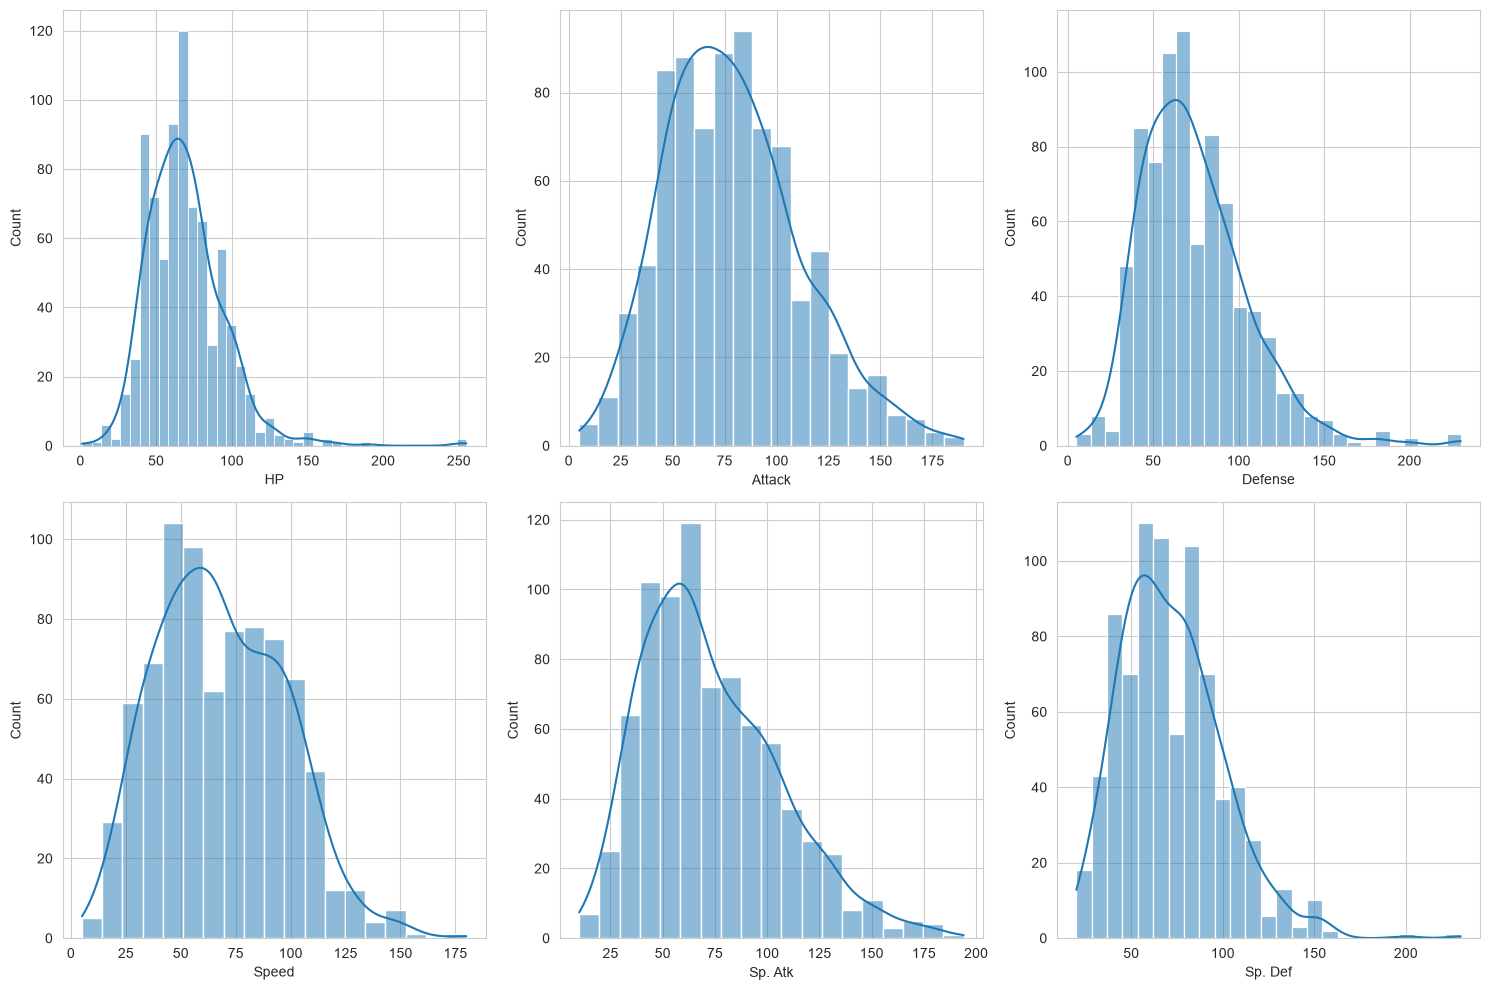

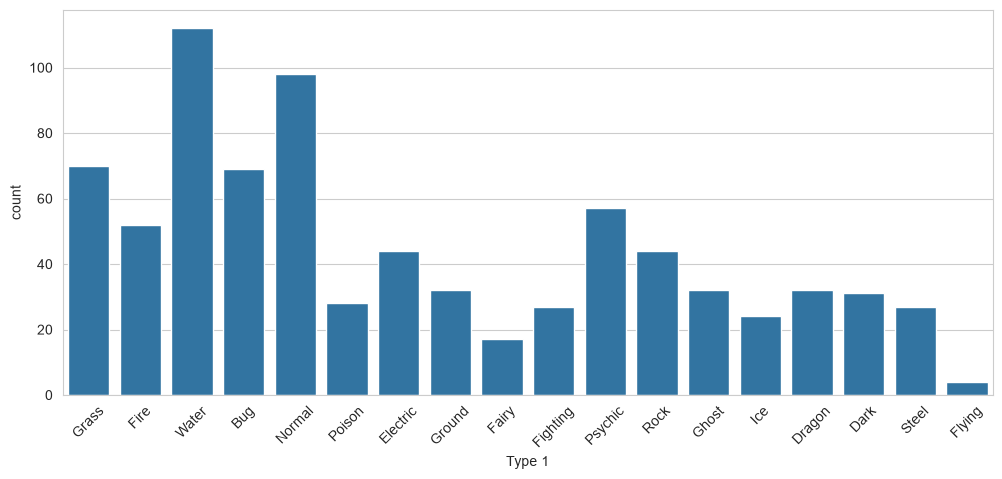

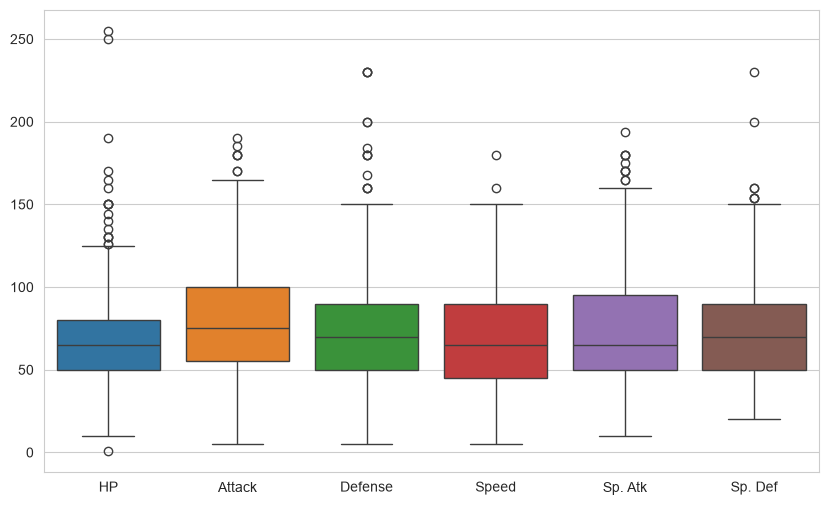

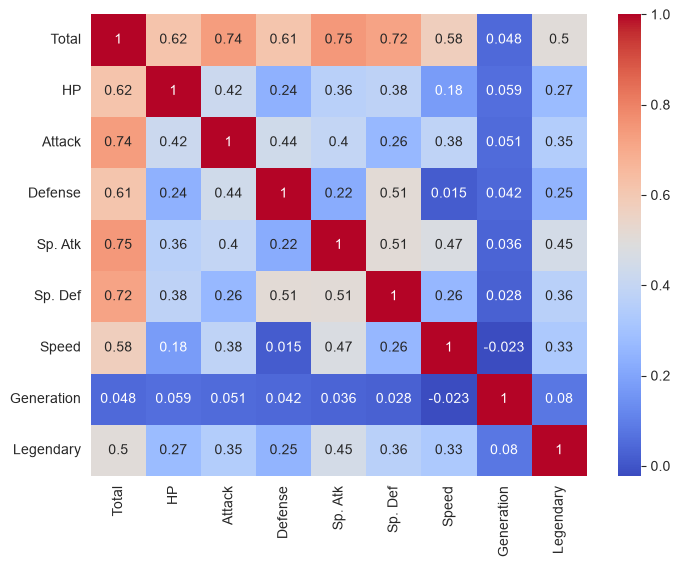

In [373]:
# 1.
numeric_cols = ['HP', 'Attack', 'Defense', 'Speed', 'Sp. Atk', 'Sp. Def']
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, col in zip(axes.flatten(), numeric_cols):
    sns.histplot(data=pokemon, x=col, ax=ax, kde=True)
plt.tight_layout()

# 2. Sí, tipos como Water y Normal están sobrerrepresentados frente a otros como Flying o Ice.
plt.figure(figsize=(12, 5))
sns.countplot(data=pokemon, x='Type 1')
plt.xticks(rotation=45)

# 3. Sí, hay bastantes valores atípicos (outliers) en las estadísticas que superan el límite superior.
plt.figure(figsize=(10, 6))
sns.boxplot(data=pokemon[numeric_cols])

# 4. La mayoría están correlacionadas positivamente. Por ejemplo Sp. Atk y Sp. Def con el resto de las estadísticas, mostrando que un Pokémon fuerte en una característica suele serlo en otras.
plt.figure(figsize=(8, 6))
sns.heatmap(pokemon.corr(numeric_only=True), annot=True, cmap="coolwarm")


## Paso 3: Limpieza de datos

1. Identifique las columnas con datos faltantes. ¿Cuál tiene más?
2. Para `Type 2`: ¿qué significa un valor faltante? ¿Tiene sentido eliminarlo o rellenarlo? Justifique su decisión.
3. Verifique si hay filas duplicadas con `duplicated().sum()`.
4. Verifique si hay valores inconsistentes en las columnas categóricas.

In [374]:
# 1. La columna 'Type 2' es la que tiene la mayoría de los datos faltantes.
print(pokemon.isnull().sum())

# 2. Significa que el Pokémon no tiene un tipo secundario (es de un solo tipo). Lo correcto es rellenarlo (ej. con "None") porque la ausencia de dato contiene información.
pokemon['Type 2'] = pokemon['Type 2'].fillna('None')

# 3.
print("Duplicados:", pokemon.duplicated().sum())

# 4.
for col in ['Type 1', 'Type 2']:
    print(pokemon[col].value_counts())


Name            0
Type 1          0
Type 2        386
Total           0
HP              0
Attack          0
Defense         0
Sp. Atk         0
Sp. Def         0
Speed           0
Generation      0
Legendary       0
dtype: int64
Duplicados: 0
Type 1
Water       112
Normal       98
Grass        70
Bug          69
Psychic      57
Fire         52
Electric     44
Rock         44
Ground       32
Ghost        32
Dragon       32
Dark         31
Poison       28
Fighting     27
Steel        27
Ice          24
Fairy        17
Flying        4
Name: count, dtype: int64
Type 2
None        386
Flying       97
Ground       35
Poison       34
Psychic      33
Fighting     26
Grass        25
Fairy        23
Steel        22
Dark         20
Dragon       18
Ice          14
Rock         14
Water        14
Ghost        14
Fire         12
Electric      6
Normal        4
Bug           3
Name: count, dtype: int64


## Paso 4: Transformación de datos

1. Cree una columna `Total_Stats` sumando `HP`, `Attack`, `Defense`, `Sp. Atk`, `Sp. Def` y `Speed`. Compare con la columna `Total` existente.
2. Cree una columna `Attack_Category` que clasifique el ataque:
   - `Attack < 50` → "Bajo"
   - `50 <= Attack < 100` → "Medio"
   - `Attack >= 100` → "Alto"
   
   Use `pd.cut()` o una función con `map()`.
3. Transforme `Legendary` de `True/False` a `1/0` usando `astype(int)`.
4. Elimine columnas que no aporten al análisis. Justifique.

In [375]:
# 1.
pokemon['Total_Stats'] = pokemon['HP'] + pokemon['Attack'] + pokemon['Defense'] + pokemon['Sp. Atk'] + pokemon['Sp. Def'] + pokemon['Speed']

# 2.
pokemon['Attack_Category'] = pd.cut(pokemon['Attack'], bins=[-np.inf, 50, 100, np.inf], labels=["Bajo", "Medio", "Alto"], right=False)

# 3.
pokemon['Legendary'] = pokemon['Legendary'].astype(int)

# 4. Se elimina 'Total' ya que es completamente redundante con 'Total_Stats'.
pokemon = pokemon.drop(columns=['Total'])


## Paso 5: Visualización posterior a la transformación

Ahora que los datos están limpios y transformados, verifique visualmente los resultados.

1. Cree un `countplot` de `Attack_Category`. ¿Cómo se distribuyen los Pokémon?
2. Cree un `boxplot` de `Total_Stats` por `Attack_Category`.
3. Cree un `scatterplot` de `Attack` vs `Defense`, coloreado por `Attack_Category`.
4. Compare con las visualizaciones del Paso 2. ¿Qué insights nuevos obtiene?

<Axes: xlabel='Attack', ylabel='Defense'>

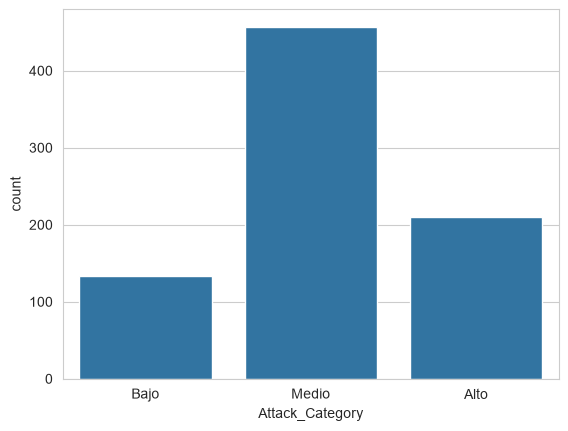

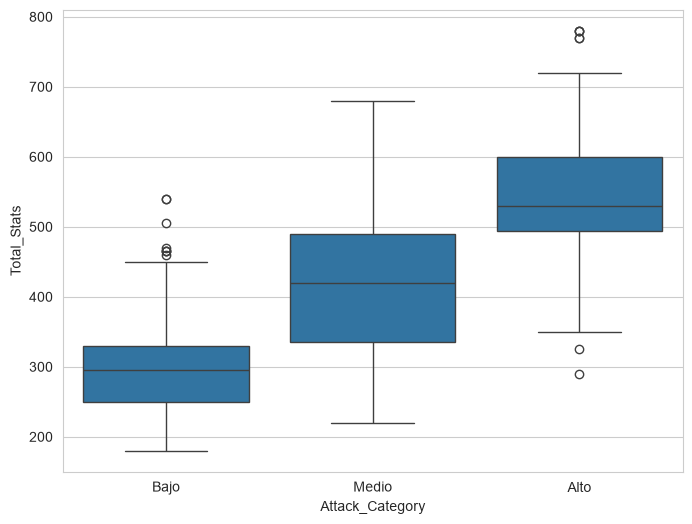

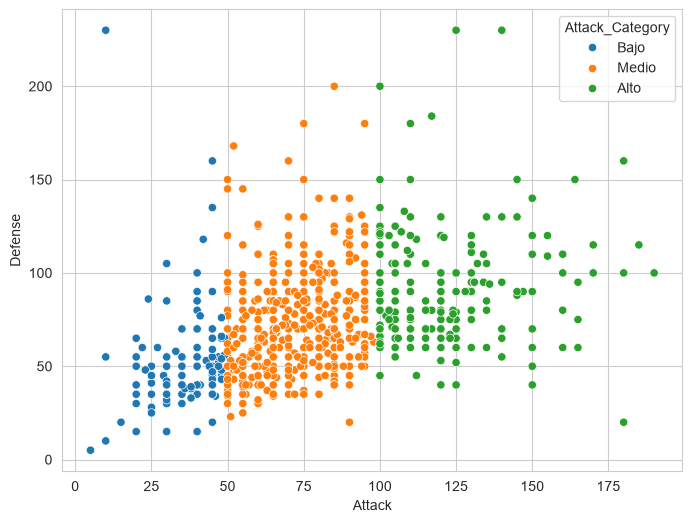

In [376]:
# 1. La mayoría se distribuyen en Medio y Alto, con una menor proporción en Bajo.
sns.countplot(data=pokemon, x='Attack_Category')

# 2.
plt.figure(figsize=(8, 6))
sns.boxplot(data=pokemon, x='Attack_Category', y='Total_Stats')

# 3.
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pokemon, x='Attack', y='Defense', hue='Attack_Category')

# 4. Ahora se puede apreciar claramente cómo se agrupan los Pokémon según su categoría de ataque generada, lo cual segmenta de forma marcada su total de estadísticas.


## Paso 6: Conclusiones

Escriba un resumen con:

1. Las características más importantes del dataset.
2. Las relaciones encontradas entre variables.
3. Los problemas de calidad de datos y cómo los resolvió.
4. Las transformaciones realizadas y su justificación.

1. Características importantes:
El dataset contiene estadísticas base de combate  y características categóricas de 800 Pokémon. Se identificaron tipos predominantes (Water, Normal) y valores numéricos con una alta variabilidad y presencia de valores atípicos (outliers).

2. Relaciones encontradas:
Existe una fuerte correlación positiva entre casi todas las estadísticas base; un Pokémon con alto ataque o ataque especial tiende a tener mejores estadísticas generales. El tipo primario y la categoría de ataque segmentan claramente el desempeño global (Total_Stats).

3. Calidad de datos y resolución:
El principal problema detectado fue la gran cantidad de datos faltantes en la columna Type 2 . En lugar de eliminar estas filas, lo cual resultaría en una gran pérdida de información, se rellenaron los nulos con None, ya que la ausencia del dato indica legítimamente que el Pokémon es de un único tipo.

4. Transformaciones y justificación:
- Total_Stats: Se calculó sumando todas las estadísticas base para validar y reemplazar la columna Total existente, eliminando así redundancias.
- Attack_Category: Se discretizó el Attack en tres niveles (Bajo, Medio, Alto) para facilitar el análisis comparativo categórico y los diagramas de caja.
- Legendary: Se transformó de booleano (True/False) a numérico (1/0) para compatibilidad con posibles modelos analíticos futuros.



# III. APLICANDO

En esta sección aplicará de forma **autónoma** todo lo aprendido. Trabajará con tres datasets, cada uno representando un tipo de problema distinto. Para cada uno debe:

1. Realizar el proceso completo de **análisis y preprocesamiento**.
2. **Proponer una hipótesis del modelo** que podría resolver el problema.

## Predicción Numérica (Regresión)

**Dataset:** `data/penguins.csv` <cite data-cite="palmerpenguins"></cite>

![palmerpenguins](./images/palmerpenguins.png)

**Objetivo:** Predecir la masa corporal (`body_mass_g`) de un pingüino a partir de sus otras características.

1. **Carga y exploración:** Use `read_csv()`, `info()`, `describe()`, `head()`.
2. **Visualización exploratoria:** Al menos 3 gráficos que muestren relaciones con `body_mass_g`.
3. **Limpieza:** Identifique y maneje datos faltantes. Justifique.
4. **Transformación:** Realice las transformaciones necesarias.
5. **Hipótesis del modelo:** ¿Qué variables son más importantes para predecir `body_mass_g`? ¿Qué tipo de modelo sugeriría? Justifique.

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB
None
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count      342.000000     342.000000         342.000000   342.000000
mean        43.921930      17.151170         200.915205  4201.754386
std          5.459584       1.974793          14.061714   801.954536
min         32.100000      13.100000         172.000000  2700.000000
25%         39.225000      15.600000         190.000000  3550.000000
50%    

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


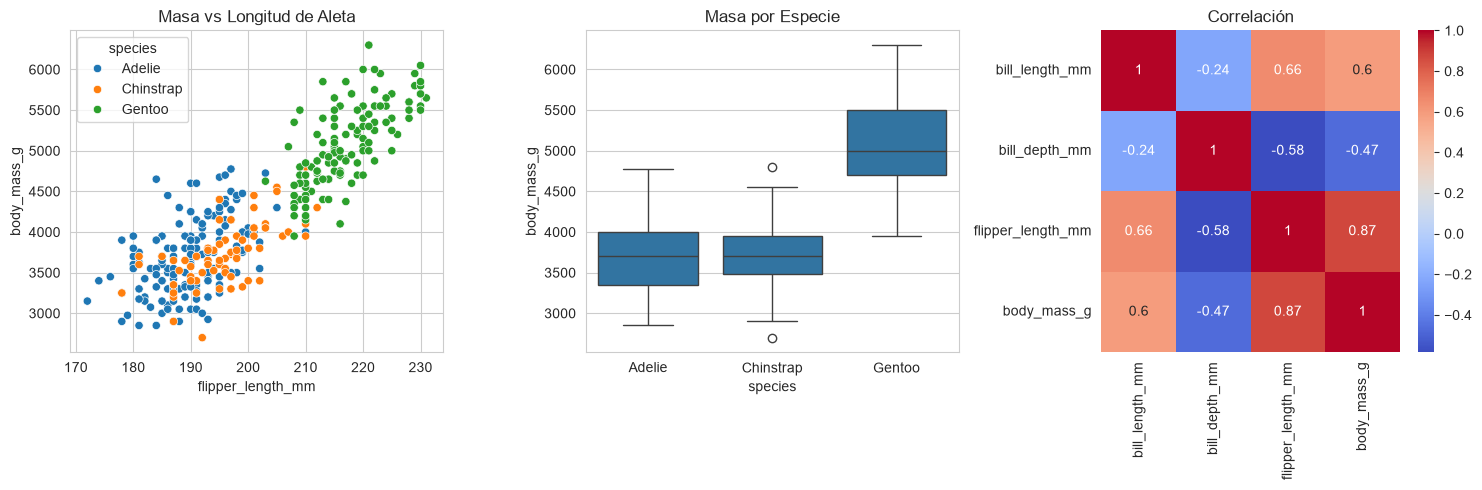

Faltantes antes:
 species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


'\nHipótesis:\n- Las variables más importantes para predecir `body_mass_g` son `flipper_length_mm` (altísima correlación positiva) y la especie (`species`), ya que los pingüinos Gentoo son notablemente más pesados.\n- Modelo sugerido: Un modelo de Regresión Lineal Múltiple. Justificación: Se busca predecir un valor numérico continuo (masa) y existe una relación lineal muy fuerte y evidente en los gráficos de dispersión.\n'

In [377]:


# 1. Carga y exploración
penguins = pd.read_csv('data/penguins.csv')
print(penguins.info())
print(penguins.describe())
display(penguins.head())

# 2. Visualización exploratoria
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.scatterplot(data=penguins, x='flipper_length_mm', y='body_mass_g', hue='species')
plt.title("Masa vs Longitud de Aleta")

plt.subplot(1, 3, 2)
sns.boxplot(data=penguins, x='species', y='body_mass_g')
plt.title("Masa por Especie")

plt.subplot(1, 3, 3)
sns.heatmap(penguins.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title("Correlación")
plt.tight_layout()
plt.show()

# 3. Limpieza
# Identificamos faltantes
print("Faltantes antes:\n", penguins.isnull().sum())
# Justificación: Al ser una cantidad muy pequeña de registros nulos (generalmente ~2%), 
# la forma más limpia y segura es eliminarlos con dropna() para no introducir sesgos.
penguins = penguins.dropna()

# 4. Transformación
# Convertimos la variable categórica 'sex' a numérica (Binaria) para que el modelo matemático pueda entenderla.
penguins['sex_num'] = penguins['sex'].map({'MALE': 1, 'FEMALE': 0, 'male': 1, 'female': 0})

# 5. Hipótesis del modelo
"""
Hipótesis:
- Las variables más importantes para predecir `body_mass_g` son `flipper_length_mm` (altísima correlación positiva) y la especie (`species`), ya que los pingüinos Gentoo son notablemente más pesados.
- Modelo sugerido: Un modelo de Regresión Lineal Múltiple. Justificación: Se busca predecir un valor numérico continuo (masa) y existe una relación lineal muy fuerte y evidente en los gráficos de dispersión.
"""


## Clasificación

**Dataset:** `data/titanic.csv` <cite data-cite="titanic"></cite>

![titanic](./images/titanic.png)

**Objetivo:** Predecir si un pasajero sobrevivió (`survived`) al naufragio del Titanic.

1. **Carga y exploración:** Use `read_csv()`, `info()`, `describe()`, `head()`.
2. **Visualización exploratoria:** Al menos 3 gráficos que muestren factores de supervivencia.
3. **Limpieza:** Identifique y maneje datos faltantes. Justifique.
4. **Transformación:** Codifique variables categóricas si es necesario.
5. **Hipótesis del modelo:** ¿Qué variables predicen mejor la supervivencia? ¿Qué modelo sugeriría? Justifique.

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB
None
         survived      pclass         age       sibsp       parch        fare
count  891.000000  891.000000  714.000000

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


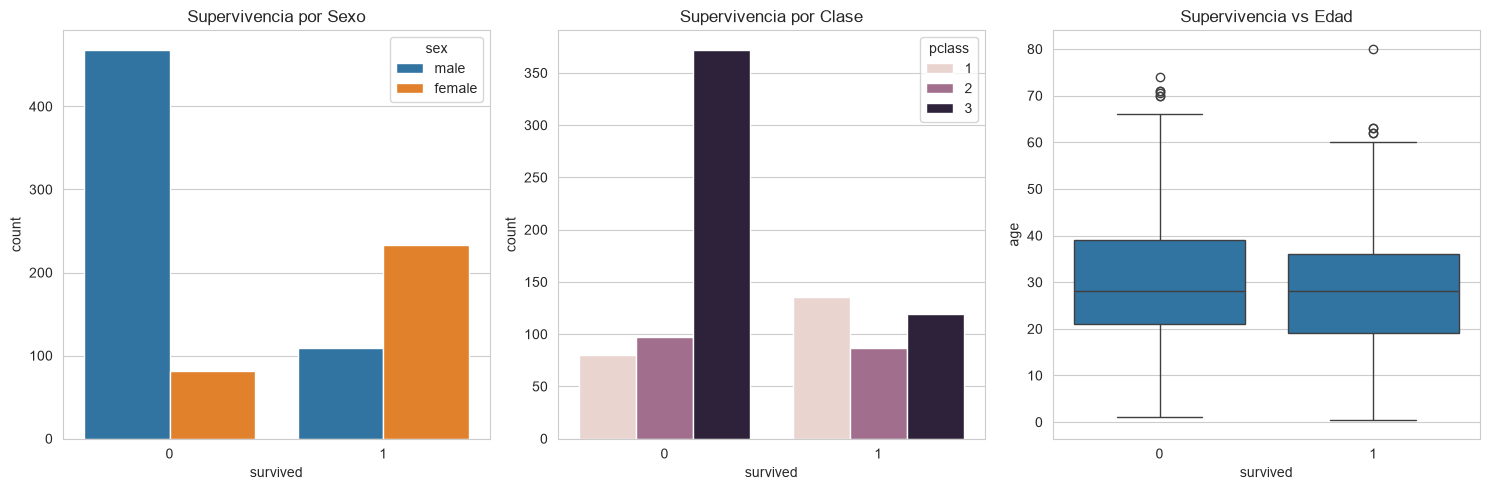

Faltantes antes:
 survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


'\nHipótesis:\n- Las variables que mejor predicen la supervivencia son `sex` (las mujeres sobrevivieron en mayor proporción) y `pclass` (la primera clase tuvo mayor supervivencia).\n- Modelo sugerido: Regresión Logística o Bosque Aleatorio (Random Forest) de Clasificación. Justificación: La variable objetivo es binaria (Sobrevive 1 / No sobrevive 0) y estos algoritmos son robustos para determinar probabilidades de pertenencia a una clase.\n'

In [378]:
# 1. Carga y exploración
titanic = pd.read_csv('data/titanic.csv')
print(titanic.info())
print(titanic.describe())
display(titanic.head())

# 2. Visualización exploratoria
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.countplot(data=titanic, x='survived', hue='sex')
plt.title("Supervivencia por Sexo")

plt.subplot(1, 3, 2)
sns.countplot(data=titanic, x='survived', hue='pclass')
plt.title("Supervivencia por Clase")

plt.subplot(1, 3, 3)
sns.boxplot(data=titanic, x='survived', y='age')
plt.title("Supervivencia vs Edad")
plt.tight_layout()
plt.show()

# 3. Limpieza
print("Faltantes antes:\n", titanic.isnull().sum())
# Justificación: 'age' tiene muchos faltantes, así que se imputa con la mediana para mantener la distribución. 
# 'deck' (si existe) tiene demasiados nulos, por lo que se descartaría, y 'embark_town' se eliminan las 2 filas nulas.
titanic['age'] = titanic['age'].fillna(titanic['age'].median())
titanic = titanic.dropna(subset=['embark_town'])

# 4. Transformación
# Codificamos 'sex' a numérico
titanic['sex_num'] = titanic['sex'].map({'male': 0, 'female': 1})

# 5. Hipótesis del modelo
"""
Hipótesis:
- Las variables que mejor predicen la supervivencia son `sex` (las mujeres sobrevivieron en mayor proporción) y `pclass` (la primera clase tuvo mayor supervivencia).
- Modelo sugerido: Regresión Logística o Bosque Aleatorio (Random Forest) de Clasificación. Justificación: La variable objetivo es binaria (Sobrevive 1 / No sobrevive 0) y estos algoritmos son robustos para determinar probabilidades de pertenencia a una clase.
"""


## Agrupamiento (Clustering)

**Dataset:** `data/pokemon.csv`

![pokemon](./images/pokemon.png)

**Objetivo:** Agrupar los Pokémon en categorías significativas basándose en sus datos de combate.

1. **Carga y exploración:** Seleccione las columnas numéricas de datos (`HP`, `Attack`, `Defense`, `Sp. Atk`, `Sp. Def`, `Speed`).
2. **Visualización exploratoria:** Al menos 3 gráficos para identificar posibles grupos naturales (`pairplot`, `scatterplot`, `heatmap`).
3. **Limpieza y transformación:** Maneje datos faltantes. Considere si necesita normalizar las variables.
4. **Hipótesis del modelo:** ¿Cuántos grupos naturales cree que existen? ¿Qué variables distinguen mejor los grupos? ¿Qué modelo sugeriría? Justifique.

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   HP       800 non-null    int64
 1   Attack   800 non-null    int64
 2   Defense  800 non-null    int64
 3   Sp. Atk  800 non-null    int64
 4   Sp. Def  800 non-null    int64
 5   Speed    800 non-null    int64
dtypes: int64(6)
memory usage: 37.6 KB
None
               HP      Attack     Defense     Sp. Atk     Sp. Def       Speed
count  800.000000  800.000000  800.000000  800.000000  800.000000  800.000000
mean    69.258750   79.001250   73.842500   72.820000   71.902500   68.277500
std     25.534669   32.457366   31.183501   32.722294   27.828916   29.060474
min      1.000000    5.000000    5.000000   10.000000   20.000000    5.000000
25%     50.000000   55.000000   50.000000   49.750000   50.000000   45.000000
50%     65.000000   75.000000   70.000000   65.000000   70.000000   65.000000
75%     80.000000  100.000000

,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed
0,45,49,49,65,65,45
1,60,62,63,80,80,60
2,80,82,83,100,100,80
3,80,100,123,122,120,80
4,39,52,43,60,50,65


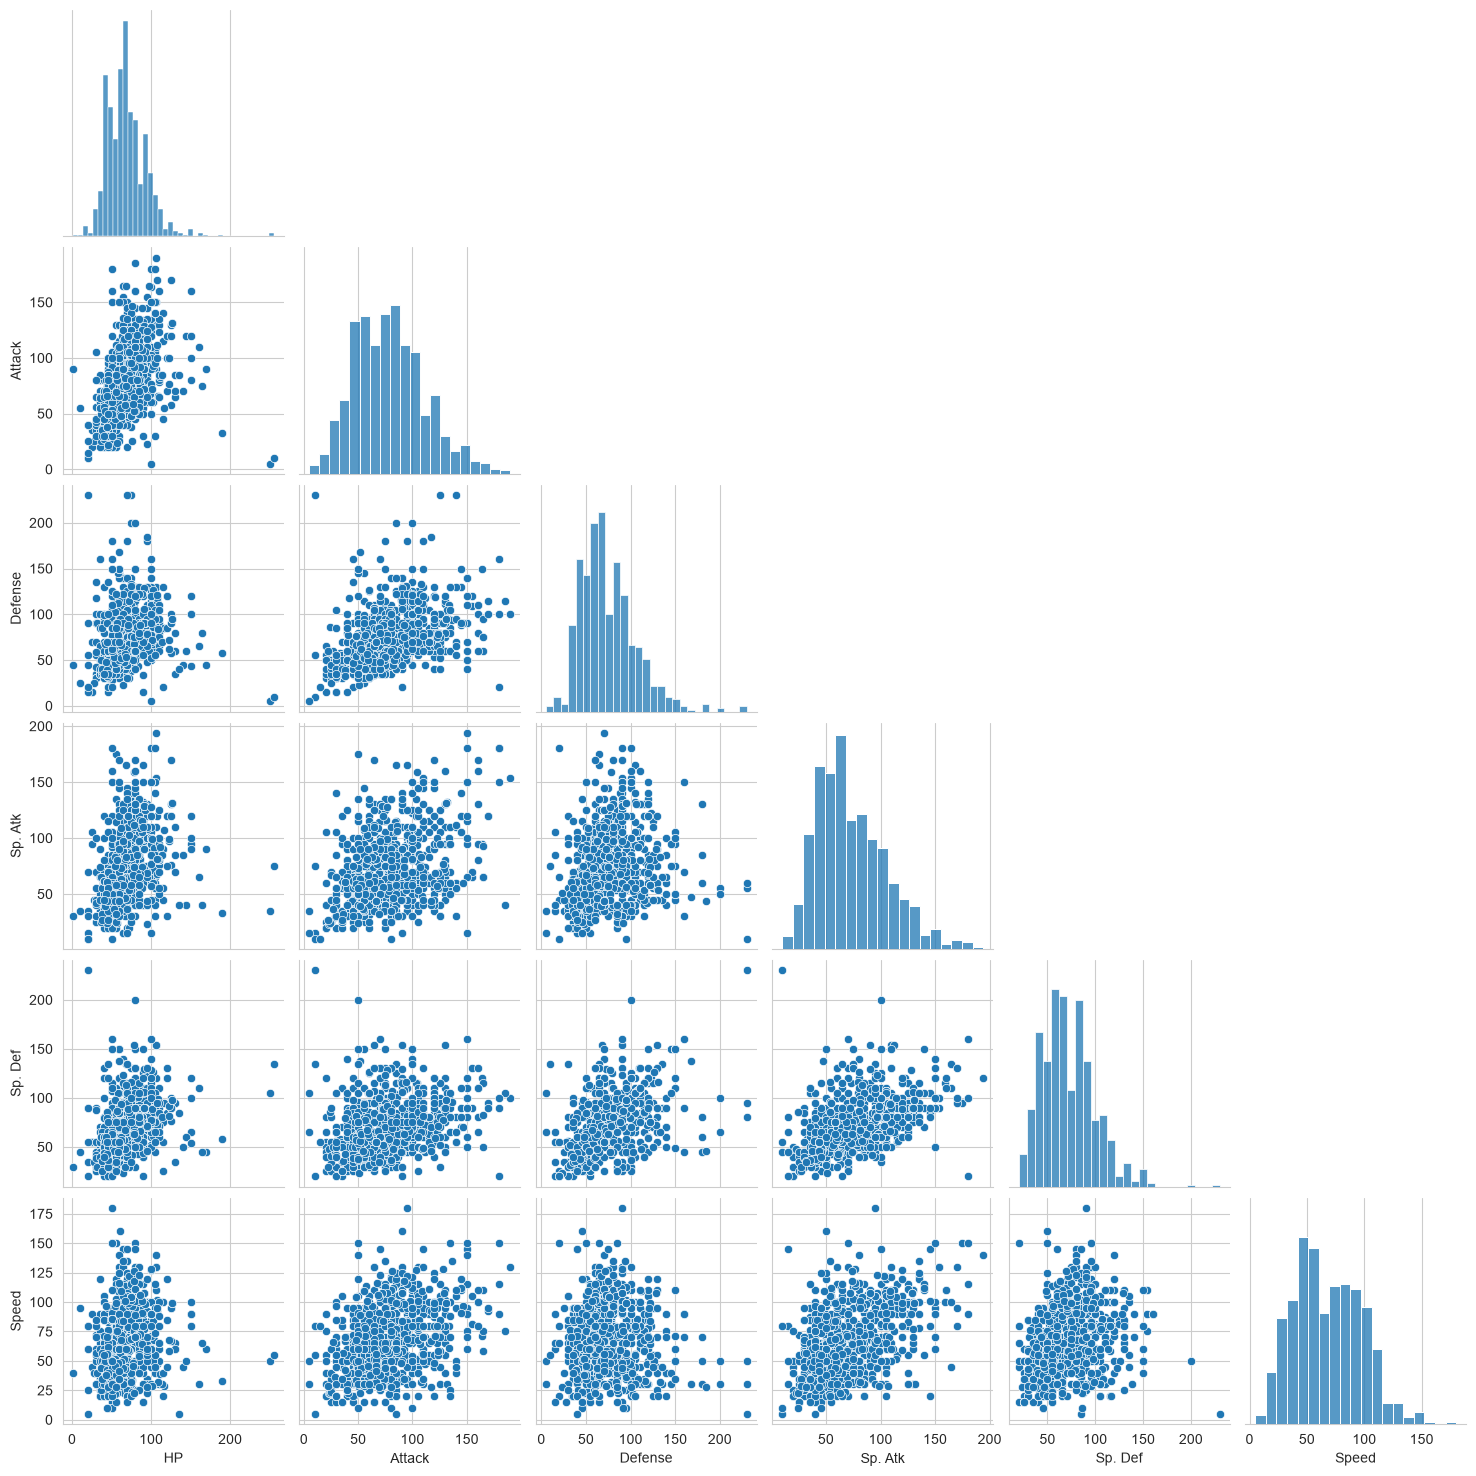

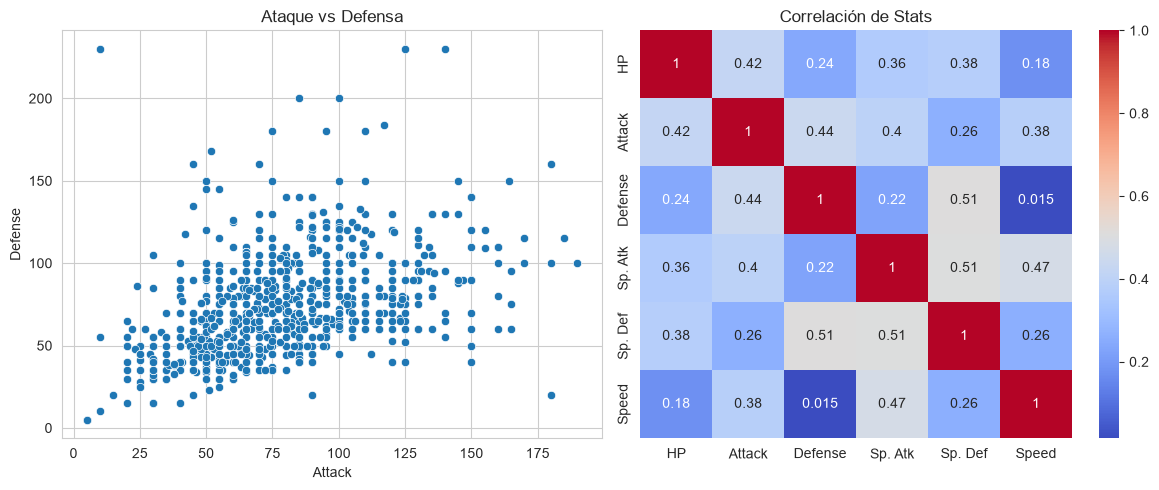

Faltantes antes:
 HP         0
Attack     0
Defense    0
Sp. Atk    0
Sp. Def    0
Speed      0
dtype: int64
Defaulting to user installation because normal site-packages is not writeable
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
      The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
      rather than 'sklearn' for pip commands.
      
      Here is how to fix this error in the main use cases:
      - use 'pip install scikit-learn' rather than 'pip install sklearn'
      - replace 'sklearn' by 'scikit-learn' in your pip requirements files
        (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
      - if the 'sklearn' package is used by one of your dependencies,
        it would be great if you take some time to track which package uses
        'sklearn' instead of 'scikit-learn' and report it to their issue tracker
      - as a last resort, set the environment variable
        SKLEARN_ALLOW_DEPRECATED_SKLEARN_PACKAGE_INSTALL=True to avoid this error
      
      More information is available at
      https://github.com/scikit-learn/sklearn-

ModuleNotFoundError: No module named 'sklearn'

In [ ]:
# 1. Carga y exploración
pokemon = pd.read_csv('data/pokemon.csv')
# Seleccionamos únicamente las columnas numéricas de combate
pokemon_num = pokemon[['HP', 'Attack', 'Defense', 'Sp. Atk', 'Sp. Def', 'Speed']]

print(pokemon_num.info())
print(pokemon_num.describe())
display(pokemon_num.head())

# 2. Visualización exploratoria
sns.pairplot(pokemon_num, corner=True)
plt.show()

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.scatterplot(data=pokemon_num, x='Attack', y='Defense')
plt.title("Ataque vs Defensa")

plt.subplot(1, 2, 2)
sns.heatmap(pokemon_num.corr(), annot=True, cmap='coolwarm')
plt.title("Correlación de Stats")
plt.tight_layout()
plt.show()

# 3. Limpieza y transformación
print("Faltantes antes:\n", pokemon_num.isnull().sum())
# Justificación de limpieza: 
# Como verificamos arriba, estas columnas numéricas no tienen datos nulos.
# Por lo tanto, no es necesario eliminar filas ni imputar valores.


# 4. Hipótesis del modelo
"""
Hipótesis:
- A partir de los gráficos  se evidencia una fuerte correlación positiva entre atributos como Defensa y Defensa Especial, así como Ataque y Ataque Especial. Los atributos permiten agrupar a los Pokémon en "Tiers" o categorías de poder general basándose en sus stats totales y distribuciones de poder. 
- Podrían existir de manera natural entre 3 y 5 grupos (por ejemplo: débiles, tanques/defensivos, rápidos/ofensivos, fuertes/legendarios).

- Modelo sugerido: K-Means
- Justificación: Dado que no tenemos una variable objetivo, nos enfrentamos a un problema de Aprendizaje No Supervisado. K-Means es un algoritmo excelente para este propósito ya que agrupará a los Pokémon basándose directamente en la similitud de sus características de combate normalizadas.
"""


# IV. RETROSPECTIVA

1. ¿Cuál fue el tiempo total invertido en el laboratorio por cada uno de ustedes? (Horas/Hombre)
Juan Diego Gaitan 7 horas, Juan Diego Murillo 7 horas
2. ¿Cuál es el estado actual del laboratorio? ¿Por qué?
Completado
3. ¿Cuál consideran fue el mayor logro? ¿Por qué?
Organizarse y entender
4. ¿Cuál consideran que fue el mayor problema técnico? ¿Qué hicieron para resolverlo?
Entender las graficas y analizar las hipotesis
5. ¿Qué hicieron bien como equipo? ¿Qué se comprometen a hacer para mejorar los resultados?
Trabajo en equipo y disposición al trabajo. Organizar mejor el tiempo